# 회귀 실습

현대 중공업과 계약을 맺어 일부 선박에 대한 예측 모델을 구축하게됐습니다. 현대 중공업은 세계 최대의 선박 제조업체 중 하나로 유람선을 제작하고 있습니다.
당신은 선박에 필요한 선원 수를 정확하게 예측할 수 있도록 울산에있는 본사에 도착했습니다.
그들은 현재 새로운 선박을 건조하고 있으며 예측 모델을 만들고, 이를 사용하여 선박에 필요한 승무원 수를 예측하기를 원합니다.
    
데이터는 "cruise_ship_info.csv"라는 csv 파일에 저장됩니다. 귀하의 임무는 향후 선박에 필요한 선원 수를 예측하는 데 도움이되는 회귀 모델을 만드는 것입니다. 고객은 또한 특정 크루즈 라인이 허용되는 승무원 수에 차이가 있음을 발견 했으므로 분석에 포함하는 것이 가장 중요한 기능이라고 언급했습니다!

In [768]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from sklearn.preprocessing import PolynomialFeatures

In [9]:
# Windows용 한글 폰트 오류 해결
from pathlib import Path
from sys import platform
from matplotlib import font_manager, rc
font_path = {
    "win32": "C:/Windows/Fonts/malgun.ttf",
    "darwin": "/System/Library/Fonts/Supplemental/AppleGothic.ttf",
}.get(platform)
if font_path is not None and Path(font_path).is_file():
    font_name = font_manager.FontProperties(fname = font_path).get_name()
    rc("font", family = font_name)

# 데이터 확인

In [3]:
df = pd.read_csv("./과제/회귀/cruise_ship_info.csv")

In [5]:
df.head()

,Ship_name,Cruise_line,Age,Tonnage,passengers,length,cabins,passenger_density,crew
0,Journey,Azamara,6,30.277,6.94,5.94,3.55,42.64,3.55
1,Quest,Azamara,6,30.277,6.94,5.94,3.55,42.64,3.55
2,Celebration,Carnival,26,47.262,14.86,7.22,7.43,31.80,6.70
3,Conquest,Carnival,11,110.000,29.74,9.53,14.88,36.99,19.10
4,Destiny,Carnival,17,101.353,26.42,8.92,13.21,38.36,10.00


In [13]:
df.shape

(158, 9)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158 entries, 0 to 157
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Ship_name          158 non-null    object 
 1   Cruise_line        158 non-null    object 
 2   Age                158 non-null    int64  
 3   Tonnage            158 non-null    float64
 4   passengers         158 non-null    float64
 5   length             158 non-null    float64
 6   cabins             158 non-null    float64
 7   passenger_density  158 non-null    float64
 8   crew               158 non-null    float64
dtypes: float64(6), int64(1), object(2)
memory usage: 11.2+ KB


In [17]:
df["Cruise_line"].unique()

array(['Azamara', 'Carnival', 'Celebrity', 'Costa', 'Crystal', 'Cunard',
       'Disney', 'Holland_American', 'MSC', 'Norwegian', 'Oceania',
       'Orient', 'P&O', 'Princess', 'Regent_Seven_Seas',
       'Royal_Caribbean', 'Seabourn', 'Silversea', 'Star', 'Windstar'],
      dtype=object)

In [19]:
df.describe()

,Age,Tonnage,passengers,length,cabins,passenger_density,crew
count,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000
mean,15.689873,71.284671,18.457405,8.130633,8.830000,39.900949,7.794177
std,7.615691,37.229540,9.677095,1.793474,4.471417,8.639217,3.503487
min,4.000000,2.329000,0.660000,2.790000,0.330000,17.700000,0.590000
25%,10.000000,46.013000,12.535000,7.100000,6.132500,34.570000,5.480000
50%,14.000000,71.899000,19.500000,8.555000,9.570000,39.085000,8.150000
75%,20.000000,90.772500,24.845000,9.510000,10.885000,44.185000,9.990000
max,48.000000,220.000000,54.000000,11.820000,27.000000,71.430000,21.000000


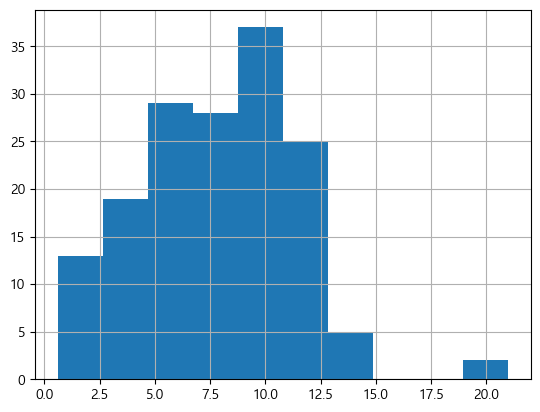

In [22]:
# crew 수 분포 히스토그램
df["crew"].hist()
plt.show()

In [26]:
crew_data = df.groupby("Cruise_line")["crew"].mean()

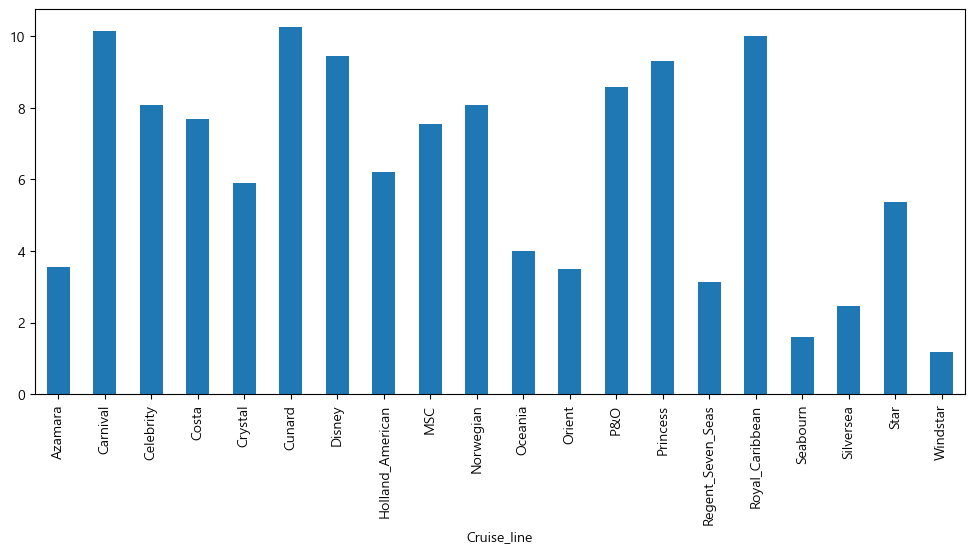

In [40]:
plt.figure(figsize = (12, 5))
crew_data.plot(kind = "bar")
plt.show()

- 고객이 분석에 꼭 포함시키라고 한 피처인 Cruise_line 시각화
    - Carnival, Cunard, Royal_Carribbean 사의 선박들의 crew 수 평균이 높은 것으로 나타남

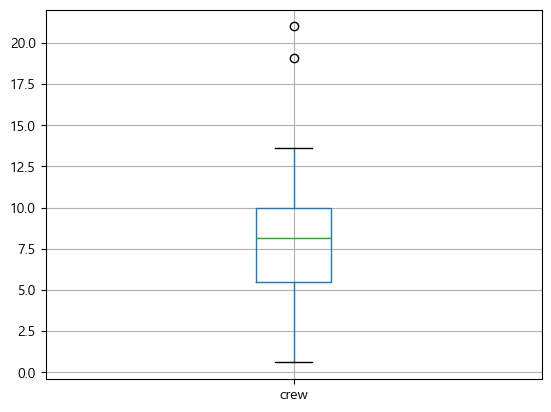

In [42]:
df.boxplot(column = ["crew"])
plt.show()

- 종속변수 분석
    - 50% 정도가 5 ~10명에 모여 있음
    - 중간값은 약 8명
    - 약 20명 정도의 이상치도 존재

In [64]:
# Cruise_line 으로 그룹화하여 평균 구함
group = df.drop("Ship_name", axis = 1).groupby("Cruise_line").mean()

In [66]:
group

,Age,Tonnage,passengers,length,cabins,passenger_density,crew
Cruise_line,,,,,,,
Azamara,6.000000,30.277000,6.940000,5.940000,3.550000,42.640000,3.550000
Carnival,15.227273,84.652727,23.458182,8.898636,11.559091,36.045909,10.135909
Celebrity,13.700000,76.158600,17.980000,8.418000,8.064000,39.534000,8.072000
Costa,16.181818,71.096545,19.200000,8.138182,9.257273,37.311818,7.700000
Crystal,14.000000,59.502000,10.100000,7.855000,5.150000,58.610000,5.905000
Cunard,20.000000,103.909000,21.370000,10.196667,10.376667,47.353333,10.246667
Disney,14.500000,83.169000,17.500000,9.640000,8.750000,47.525000,9.450000
Holland_American,17.071429,60.501214,14.213571,7.863571,7.099286,42.715000,6.215000
MSC,15.125000,63.772250,18.878750,8.121250,8.760000,32.745000,7.540000


# 데이터 전처리

In [87]:
df["Cruise_line"].unique()

array(['Azamara', 'Carnival', 'Celebrity', 'Costa', 'Crystal', 'Cunard',
       'Disney', 'Holland_American', 'MSC', 'Norwegian', 'Oceania',
       'Orient', 'P&O', 'Princess', 'Regent_Seven_Seas',
       'Royal_Caribbean', 'Seabourn', 'Silversea', 'Star', 'Windstar'],
      dtype=object)

In [69]:
# 원핫인코딩
ohe = OneHotEncoder()

In [73]:
cruise_arr = np.array(df["Cruise_line"])

In [75]:
cruise_arr = np.reshape(cruise_arr, (-1, 1))

In [77]:
cruise_name = ohe.fit_transform(cruise_arr)

In [79]:
ohe.get_feature_names_out()

array(['x0_Azamara', 'x0_Carnival', 'x0_Celebrity', 'x0_Costa',
       'x0_Crystal', 'x0_Cunard', 'x0_Disney', 'x0_Holland_American',
       'x0_MSC', 'x0_Norwegian', 'x0_Oceania', 'x0_Orient', 'x0_P&O',
       'x0_Princess', 'x0_Regent_Seven_Seas', 'x0_Royal_Caribbean',
       'x0_Seabourn', 'x0_Silversea', 'x0_Star', 'x0_Windstar'],
      dtype=object)

In [81]:
cruise_name

<158x20 sparse matrix of type '<class 'numpy.float64'>'
	with 158 stored elements in Compressed Sparse Row format>

In [83]:
ohe_cruise_df = pd.DataFrame(cruise_name.toarray(), columns = ohe.get_feature_names_out())

In [85]:
ohe_cruise_df.head()

,x0_Azamara,x0_Carnival,x0_Celebrity,x0_Costa,x0_Crystal,x0_Cunard,x0_Disney,x0_Holland_American,x0_MSC,x0_Norwegian,x0_Oceania,x0_Orient,x0_P&O,x0_Princess,x0_Regent_Seven_Seas,x0_Royal_Caribbean,x0_Seabourn,x0_Silversea,x0_Star,x0_Windstar
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [93]:
ohe_cruise_df.shape

(158, 20)

In [91]:
df.shape

(158, 9)

In [95]:
df = pd.concat([df.reset_index(drop = True), ohe_cruise_df], axis = 1)

In [97]:
df.head()

,Ship_name,Cruise_line,Age,Tonnage,passengers,length,cabins,passenger_density,crew,x0_Azamara,...,x0_Oceania,x0_Orient,x0_P&O,x0_Princess,x0_Regent_Seven_Seas,x0_Royal_Caribbean,x0_Seabourn,x0_Silversea,x0_Star,x0_Windstar
0,Journey,Azamara,6,30.277,6.94,5.94,3.55,42.64,3.55,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Quest,Azamara,6,30.277,6.94,5.94,3.55,42.64,3.55,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Celebration,Carnival,26,47.262,14.86,7.22,7.43,31.80,6.70,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Conquest,Carnival,11,110.000,29.74,9.53,14.88,36.99,19.10,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Destiny,Carnival,17,101.353,26.42,8.92,13.21,38.36,10.00,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [101]:
df = df.drop("Cruise_line", axis = 1)

In [103]:
df.head()

,Ship_name,Age,Tonnage,passengers,length,cabins,passenger_density,crew,x0_Azamara,x0_Carnival,...,x0_Oceania,x0_Orient,x0_P&O,x0_Princess,x0_Regent_Seven_Seas,x0_Royal_Caribbean,x0_Seabourn,x0_Silversea,x0_Star,x0_Windstar
0,Journey,6,30.277,6.94,5.94,3.55,42.64,3.55,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Quest,6,30.277,6.94,5.94,3.55,42.64,3.55,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Celebration,26,47.262,14.86,7.22,7.43,31.80,6.70,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Conquest,11,110.000,29.74,9.53,14.88,36.99,19.10,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Destiny,17,101.353,26.42,8.92,13.21,38.36,10.00,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [105]:
df.shape

(158, 28)

# 데이터 분할

In [110]:
x = df.drop(["Ship_name", "crew"], axis = 1)
y = df["crew"]

In [112]:
x.head()

,Age,Tonnage,passengers,length,cabins,passenger_density,x0_Azamara,x0_Carnival,x0_Celebrity,x0_Costa,...,x0_Oceania,x0_Orient,x0_P&O,x0_Princess,x0_Regent_Seven_Seas,x0_Royal_Caribbean,x0_Seabourn,x0_Silversea,x0_Star,x0_Windstar
0,6,30.277,6.94,5.94,3.55,42.64,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,6,30.277,6.94,5.94,3.55,42.64,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,26,47.262,14.86,7.22,7.43,31.80,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,11,110.000,29.74,9.53,14.88,36.99,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,17,101.353,26.42,8.92,13.21,38.36,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [116]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.25, random_state = 25)

In [118]:
x_train.shape, x_test.shape

((118, 26), (40, 26))

In [120]:
x_train.columns

Index(['Age', 'Tonnage', 'passengers', 'length', 'cabins', 'passenger_density',
       'x0_Azamara', 'x0_Carnival', 'x0_Celebrity', 'x0_Costa', 'x0_Crystal',
       'x0_Cunard', 'x0_Disney', 'x0_Holland_American', 'x0_MSC',
       'x0_Norwegian', 'x0_Oceania', 'x0_Orient', 'x0_P&O', 'x0_Princess',
       'x0_Regent_Seven_Seas', 'x0_Royal_Caribbean', 'x0_Seabourn',
       'x0_Silversea', 'x0_Star', 'x0_Windstar'],
      dtype='object')

In [130]:
scale_col = x_train.columns[:6].tolist()

In [134]:
scale_col

['Age', 'Tonnage', 'passengers', 'length', 'cabins', 'passenger_density']

In [136]:
x_train[scale_col].head()

,Age,Tonnage,passengers,length,cabins,passenger_density
69,31,35.143,12.50,6.69,5.32,28.11
140,15,78.491,24.35,9.15,10.00,32.23
119,12,138.000,31.14,10.20,15.57,44.32
4,17,101.353,26.42,8.92,13.21,38.36
94,10,77.000,20.16,8.56,9.75,38.19


In [138]:
ss = StandardScaler()

In [140]:
scaled_train = ss.fit_transform(x_train[scale_col])
scaled_test = ss.transform(x_test[scale_col])

In [142]:
scaled_test

array([[-0.30900417,  0.78800505,  0.90194582,  0.47861987,  0.93122903,
        -0.35845725],
       [-1.18012174,  1.1525138 ,  1.23253259,  0.786484  ,  1.42387466,
        -0.2894557 ],
       [-1.42901248,  1.12735965,  1.69071425,  0.51577588,  1.37168763,
        -0.8821904 ],
       [-1.30456711,  0.5739684 ,  0.55009324,  0.86079603,  0.67238133,
        -0.12769794],
       [ 0.5621134 , -0.80950971, -0.743255  , -1.25178888, -0.72414379,
        -0.45234462],
       [-0.80678564,  0.53943176,  0.14410949,  0.85548803,  0.23401021,
         0.7286001 ],
       [ 0.06433193,  0.18943695,  0.06291274,  0.33530381,  0.12546118,
         0.12907836],
       [-0.55789491,  0.52366011,  0.20017391,  0.86079603,  0.20896044,
         0.54308771],
       [-0.93123101,  1.07705136,  0.82074907,  0.786484  ,  0.96462874,
         0.25803209],
       [ 0.81100413, -1.13651363, -1.01391083, -0.95984876, -1.02056616,
        -0.87766571],
       [-0.93123101,  0.50076984,  0.65352243,  0.

In [144]:
scaled_train = pd.DataFrame(scaled_train, columns = scale_col)
scaled_test = pd.DataFrame(scaled_test, columns = scale_col)

In [146]:
scaled_train.head()

,Age,Tonnage,passengers,length,cabins,passenger_density
0,1.806567,-0.881375,-0.555729,-0.710373,-0.715794,-1.342578
1,-0.184559,0.209007,0.589725,0.595396,0.261147,-0.876535
2,-0.557895,1.705905,1.246065,1.152736,1.423875,0.491054
3,0.064332,0.784081,0.789817,0.473312,0.931229,-0.183125
4,-0.806786,0.171502,0.184708,0.282224,0.208960,-0.202355


In [150]:
x_train.iloc[:, 6:].head()

,x0_Azamara,x0_Carnival,x0_Celebrity,x0_Costa,x0_Crystal,x0_Cunard,x0_Disney,x0_Holland_American,x0_MSC,x0_Norwegian,x0_Oceania,x0_Orient,x0_P&O,x0_Princess,x0_Regent_Seven_Seas,x0_Royal_Caribbean,x0_Seabourn,x0_Silversea,x0_Star,x0_Windstar
69,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
140,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
119,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
94,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [152]:
# 수치형 데이터들 스케일링 후, 원핫인코딩된 cruise_line 과 컨켓
scaled_train = pd.concat([scaled_train, x_train.iloc[:, 6:].reset_index(drop = True)], axis = 1)
scaled_test = pd.concat([scaled_test, x_test.iloc[:, 6:].reset_index(drop = True)], axis = 1)

In [154]:
scaled_train.shape, scaled_test.shape

((118, 26), (40, 26))

# 모델 훈련

In [157]:
lr = LinearRegression()

In [159]:
lr.fit(x_train, y_train)

LinearRegression()

In [161]:
lr.score(x_test, y_test)

0.9320874582272783

In [163]:
y_pred = lr.predict(x_test)

In [179]:
mae = mean_absolute_error(y_test, y_pred)

In [181]:
mae

0.5090387275818478

In [173]:
mse = mean_squared_error(y_test, y_pred)

In [175]:
mse

0.45628635436921156

# 모델 최적화

In [184]:
# statsmodels 라이브러리로 회귀 분석
X = sm.add_constant(scaled_train) # 상수항 추가

In [186]:
model = sm.OLS(y_train.reset_index(drop = True), X)

In [188]:
model = model.fit()

In [190]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   crew   R-squared:                       0.947
Model:                            OLS   Adj. R-squared:                  0.933
Method:                 Least Squares   F-statistic:                     66.01
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           3.90e-48
Time:                        11:33:54   Log-Likelihood:                -149.66
No. Observations:                 118   AIC:                             351.3
Df Residuals:                      92   BIC:                             423.4
Df Model:                          25                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    7.5516      0.141     53.687      0.000       7.272       7.831
Age                      0.1094      0.171      0.641      0.523      -0.230       0.448
Tonnage                  0.9272      0.692      1.340      0.183      -0.447       2.301
passengers              -0.8971      0.640     -1.402      0.164      -2.168       0.374
length                   0.9825      0.297      3.307      0.001       0.392       1.572
cabins                   3.1068      0.759      4.094      0.000       1.600       4.614
passenger_density       -0.0240      0.238     -0.101      0.920      -0.496       0.448
x0_Azamara               0.5591      0.763      0.733      0.466      -0.957       2.075
x0_Carnival              0.4727      0.338      1.399      0.165      -0.198       1.144
x0_Celebrity             0.8756      0.423      2.071      0.041       0.036       1.715
x0_Costa                -0.3706      0.406     -0.913      0.363      -1.177       0.435
x0_Crystal               0.4047      0.724      0.559      0.578      -1.033       1.843
x0_Cunard                0.2200      0.878      0.251      0.803      -1.524       1.964
x0_Disney                0.7368      0.712      1.036      0.303      -0.676       2.150
x0_Holland_American     -0.3164      0.321     -0.987      0.326      -0.953       0.320
x0_MSC                   0.2707      0.421      0.643      0.522      -0.565       1.107
x0_Norwegian             0.4184      0.439      0.954      0.343      -0.453       1.290
x0_Oceania               0.9757      0.587      1.661      0.100      -0.191       2.142
x0_Orient               -0.1708      1.055     -0.162      0.872      -2.266       1.924
x0_P&O                   0.0721      0.498      0.145      0.885      -0.918       1.062
x0_Princess              0.1263      0.331      0.381      0.704      -0.531       0.784
x0_Regent_Seven_Seas     1.0560      0.615      1.717      0.089      -0.165       2.277
x0_Royal_Caribbean      -1.2885      0.369     -3.493      0.001      -2.021      -0.556
x0_Seabourn              0.8612      0.640      1.346      0.182      -0.409       2.132
x0_Silversea             0.7497      0.743      1.009      0.316      -0.726       2.225
x0_Star                  1.7449      0.498      3.506      0.001       0.756       2.733
x0_Windstar              0.1543      0.588      0.263      0.794      -1.013       1.322
==============================================================================
Omnibus:                      143.103   Durbin-Watson:                   1.984
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4227.641
Skew:                           4.250   Prob(JB):                         0.00
Kurtosis:                      31.064   Cond. No.                     3.37e+16
==================

In [192]:
# 피처마다 VIF 계수 출력
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif["feature"] = X.columns
vif.round(1)

C:\Users\ITSC\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1783: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr/self.centered_tss
C:\Users\ITSC\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,VIF_Factor,feature
0,0.0,const
1,3.6,Age
2,59.5,Tonnage
3,50.9,passengers
4,11.0,length
5,71.6,cabins
6,7.0,passenger_density
7,inf,x0_Azamara
8,inf,x0_Carnival
9,inf,x0_Celebrity


# 변수제거 1

- 제거된 변수: passenger_density

In [195]:
new_X = X.drop("passenger_density", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   crew   R-squared:                       0.947
Model:                            OLS   Adj. R-squared:                  0.934
Method:                 Least Squares   F-statistic:                     69.50
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           4.64e-49
Time:                        11:35:22   Log-Likelihood:                -149.66
No. Observations:                 118   AIC:                             349.3
Df Residuals:                      93   BIC:                             418.6
Df Model:                          24                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    7.5484      0.136     55.371      0.000       7.278       7.819
Age                      0.1136      0.165      0.690      0.492      -0.213       0.441
Tonnage                  0.8837      0.538      1.642      0.104      -0.185       1.953
passengers              -0.8620      0.535     -1.612      0.110      -1.924       0.200
length                   0.9775      0.291      3.355      0.001       0.399       1.556
cabins                   3.1214      0.741      4.213      0.000       1.650       4.593
x0_Azamara               0.5655      0.757      0.748      0.457      -0.937       2.068
x0_Carnival              0.4789      0.330      1.450      0.150      -0.177       1.135
x0_Celebrity             0.8899      0.396      2.245      0.027       0.103       1.677
x0_Costa                -0.3657      0.401     -0.913      0.364      -1.162       0.430
x0_Crystal               0.3850      0.694      0.555      0.580      -0.992       1.762
x0_Cunard                0.2275      0.870      0.261      0.794      -1.501       1.956
x0_Disney                0.7416      0.706      1.050      0.296      -0.661       2.144
x0_Holland_American     -0.3130      0.317     -0.987      0.326      -0.943       0.317
x0_MSC                   0.2860      0.391      0.732      0.466      -0.490       1.062
x0_Norwegian             0.4300      0.421      1.021      0.310      -0.406       1.266
x0_Oceania               0.9741      0.584      1.668      0.099      -0.186       2.134
x0_Orient               -0.1591      1.043     -0.153      0.879      -2.230       1.912
x0_P&O                   0.0806      0.488      0.165      0.869      -0.889       1.050
x0_Princess              0.1309      0.326      0.401      0.689      -0.517       0.779
x0_Regent_Seven_Seas     1.0288      0.550      1.869      0.065      -0.064       2.122
x0_Royal_Caribbean      -1.2805      0.358     -3.573      0.001      -1.992      -0.569
x0_Seabourn              0.8413      0.605      1.390      0.168      -0.361       2.044
x0_Silversea             0.7058      0.600      1.176      0.242      -0.486       1.897
x0_Star                  1.7395      0.492      3.534      0.001       0.762       2.717
x0_Windstar              0.1614      0.581      0.278      0.782      -0.991       1.314
==============================================================================
Omnibus:                      142.956   Durbin-Watson:                   1.985
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4211.909
Skew:                           4.244   Prob(JB):                         0.00
Kurtosis:                      31.011   Cond. No.                     5.41e+16
==============================================================================

Notes:
[1] Standard Errors 

In [197]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

C:\Users\ITSC\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1783: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr/self.centered_tss
C:\Users\ITSC\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,VIF_Factor,feature
0,0.0,const
1,3.4,Age
2,36.4,Tonnage
3,35.9,passengers
4,10.7,length
5,69.0,cabins
6,inf,x0_Azamara
7,inf,x0_Carnival
8,inf,x0_Celebrity
9,inf,x0_Costa


# 변수제거 2

- 제거된 변수: passenger_density, x0_Princess

In [201]:
new_X = new_X.drop("x0_Princess", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   crew   R-squared:                       0.947
Model:                            OLS   Adj. R-squared:                  0.934
Method:                 Least Squares   F-statistic:                     69.50
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           4.64e-49
Time:                        11:38:23   Log-Likelihood:                -149.66
No. Observations:                 118   AIC:                             349.3
Df Residuals:                      93   BIC:                             418.6
Df Model:                          24                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    7.6793      0.299     25.700      0.000       7.086       8.273
Age                      0.1136      0.165      0.690      0.492      -0.213       0.441
Tonnage                  0.8837      0.538      1.642      0.104      -0.185       1.953
passengers              -0.8620      0.535     -1.612      0.110      -1.924       0.200
length                   0.9775      0.291      3.355      0.001       0.399       1.556
cabins                   3.1214      0.741      4.213      0.000       1.650       4.593
x0_Azamara               0.4346      0.865      0.502      0.617      -1.284       2.153
x0_Carnival              0.3480      0.391      0.891      0.375      -0.428       1.124
x0_Celebrity             0.7590      0.507      1.496      0.138      -0.249       1.767
x0_Costa                -0.4966      0.474     -1.049      0.297      -1.437       0.444
x0_Crystal               0.2541      0.797      0.319      0.751      -1.329       1.838
x0_Cunard                0.0966      0.924      0.105      0.917      -1.737       1.930
x0_Disney                0.6107      0.781      0.782      0.436      -0.940       2.162
x0_Holland_American     -0.4439      0.439     -1.011      0.314      -1.316       0.428
x0_MSC                   0.1551      0.487      0.318      0.751      -0.812       1.122
x0_Norwegian             0.2991      0.510      0.586      0.559      -0.714       1.312
x0_Oceania               0.8432      0.705      1.196      0.235      -0.557       2.243
x0_Orient               -0.2900      1.122     -0.259      0.797      -2.517       1.937
x0_P&O                  -0.0503      0.574     -0.088      0.930      -1.191       1.090
x0_Regent_Seven_Seas     0.8979      0.689      1.303      0.196      -0.471       2.267
x0_Royal_Caribbean      -1.4114      0.402     -3.511      0.001      -2.210      -0.613
x0_Seabourn              0.7104      0.736      0.965      0.337      -0.752       2.173
x0_Silversea             0.5749      0.729      0.788      0.433      -0.874       2.023
x0_Star                  1.6086      0.606      2.653      0.009       0.405       2.813
x0_Windstar              0.0305      0.711      0.043      0.966      -1.381       1.442
==============================================================================
Omnibus:                      142.956   Durbin-Watson:                   1.985
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4211.909
Skew:                           4.244   Prob(JB):                         0.00
Kurtosis:                      31.011   Cond. No.                         36.3
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [203]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,11.2,const
1,3.4,Age
2,36.4,Tonnage
3,35.9,passengers
4,10.7,length
5,69.0,cabins
6,1.6,x0_Azamara
7,2.6,x0_Carnival
8,1.6,x0_Celebrity
9,1.6,x0_Costa


# 변수제거 3

- 제거된 변수: passenger_density, x0_Princess, x0_Windstar

In [207]:
new_X = new_X.drop("x0_Windstar", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   crew   R-squared:                       0.947
Model:                            OLS   Adj. R-squared:                  0.934
Method:                 Least Squares   F-statistic:                     73.30
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           5.34e-50
Time:                        11:40:32   Log-Likelihood:                -149.66
No. Observations:                 118   AIC:                             347.3
Df Residuals:                      94   BIC:                             413.8
Df Model:                          23                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    7.6856      0.259     29.695      0.000       7.172       8.200
Age                      0.1131      0.163      0.692      0.491      -0.211       0.437
Tonnage                  0.8856      0.534      1.659      0.100      -0.174       1.945
passengers              -0.8613      0.532     -1.620      0.109      -1.917       0.194
length                   0.9752      0.285      3.420      0.001       0.409       1.541
cabins                   3.1175      0.732      4.262      0.000       1.665       4.570
x0_Azamara               0.4236      0.822      0.515      0.607      -1.208       2.055
x0_Carnival              0.3440      0.377      0.913      0.364      -0.404       1.092
x0_Celebrity             0.7517      0.476      1.580      0.118      -0.193       1.697
x0_Costa                -0.5016      0.457     -1.097      0.275      -1.409       0.406
x0_Crystal               0.2456      0.768      0.320      0.750      -1.279       1.771
x0_Cunard                0.0930      0.915      0.102      0.919      -1.723       1.910
x0_Disney                0.6056      0.768      0.789      0.432      -0.919       2.130
x0_Holland_American     -0.4510      0.405     -1.114      0.268      -1.255       0.353
x0_MSC                   0.1487      0.461      0.322      0.748      -0.767       1.064
x0_Norwegian             0.2928      0.486      0.603      0.548      -0.672       1.257
x0_Oceania               0.8326      0.657      1.267      0.208      -0.472       2.137
x0_Orient               -0.2976      1.102     -0.270      0.788      -2.485       1.890
x0_P&O                  -0.0561      0.555     -0.101      0.920      -1.158       1.045
x0_Regent_Seven_Seas     0.8858      0.625      1.417      0.160      -0.356       2.127
x0_Royal_Caribbean      -1.4144      0.394     -3.593      0.001      -2.196      -0.633
x0_Seabourn              0.6980      0.673      1.036      0.303      -0.639       2.035
x0_Silversea             0.5633      0.674      0.836      0.405      -0.775       1.902
x0_Star                  1.5988      0.559      2.863      0.005       0.490       2.708
==============================================================================
Omnibus:                      143.044   Durbin-Watson:                   1.985
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4220.607
Skew:                           4.248   Prob(JB):                         0.00
Kurtosis:                      31.040   Cond. No.                         30.0
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [209]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,8.5,const
1,3.4,Age
2,36.2,Tonnage
3,35.9,passengers
4,10.3,length
5,68.0,cabins
6,1.4,x0_Azamara
7,2.4,x0_Carnival
8,1.4,x0_Celebrity
9,1.5,x0_Costa


# 변수제거 4

- 제거된 변수: passenger_density, x0_Princess, x0_Windstar, x0_P&O

In [213]:
new_X = new_X.drop("x0_P&O", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   crew   R-squared:                       0.947
Model:                            OLS   Adj. R-squared:                  0.935
Method:                 Least Squares   F-statistic:                     77.43
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           6.01e-51
Time:                        11:41:55   Log-Likelihood:                -149.67
No. Observations:                 118   AIC:                             345.3
Df Residuals:                      95   BIC:                             409.1
Df Model:                          22                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    7.6734      0.227     33.734      0.000       7.222       8.125
Age                      0.1138      0.162      0.701      0.485      -0.209       0.436
Tonnage                  0.8889      0.530      1.678      0.097      -0.163       1.941
passengers              -0.8604      0.529     -1.627      0.107      -1.910       0.189
length                   0.9705      0.280      3.468      0.001       0.415       1.526
cabins                   3.1178      0.728      4.284      0.000       1.673       4.562
x0_Azamara               0.4361      0.808      0.540      0.591      -1.168       2.040
x0_Carnival              0.3566      0.353      1.009      0.316      -0.345       1.058
x0_Celebrity             0.7643      0.457      1.673      0.098      -0.143       1.671
x0_Costa                -0.4894      0.439     -1.116      0.267      -1.360       0.381
x0_Crystal               0.2594      0.752      0.345      0.731      -1.233       1.752
x0_Cunard                0.1067      0.900      0.119      0.906      -1.680       1.894
x0_Disney                0.6211      0.749      0.830      0.409      -0.865       2.107
x0_Holland_American     -0.4380      0.382     -1.147      0.254      -1.196       0.320
x0_MSC                   0.1616      0.441      0.366      0.715      -0.714       1.037
x0_Norwegian             0.3050      0.468      0.652      0.516      -0.624       1.234
x0_Oceania               0.8444      0.643      1.313      0.192      -0.432       2.121
x0_Orient               -0.2887      1.092     -0.264      0.792      -2.457       1.880
x0_Regent_Seven_Seas     0.8967      0.613      1.463      0.147      -0.320       2.113
x0_Royal_Caribbean      -1.4025      0.373     -3.755      0.000      -2.144      -0.661
x0_Seabourn              0.7073      0.664      1.066      0.289      -0.610       2.025
x0_Silversea             0.5756      0.660      0.873      0.385      -0.734       1.885
x0_Star                  1.6084      0.547      2.938      0.004       0.522       2.695
==============================================================================
Omnibus:                      143.032   Durbin-Watson:                   1.983
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4216.767
Skew:                           4.248   Prob(JB):                         0.00
Kurtosis:                      31.026   Cond. No.                         28.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [215]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,6.6,const
1,3.4,Age
2,36.0,Tonnage
3,35.9,passengers
4,10.1,length
5,68.0,cabins
6,1.4,x0_Azamara
7,2.2,x0_Carnival
8,1.3,x0_Celebrity
9,1.4,x0_Costa


# 변수제거 5

- 제거된 변수: passenger_density, x0_Princess, x0_Windstar, x0_P&O, x0_Cunard

In [219]:
new_X = new_X.drop("x0_Cunard", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   crew   R-squared:                       0.947
Model:                            OLS   Adj. R-squared:                  0.936
Method:                 Least Squares   F-statistic:                     81.96
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           6.59e-52
Time:                        11:43:39   Log-Likelihood:                -149.68
No. Observations:                 118   AIC:                             343.4
Df Residuals:                      96   BIC:                             404.3
Df Model:                          21                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    7.6790      0.221     34.698      0.000       7.240       8.118
Age                      0.1232      0.141      0.876      0.383      -0.156       0.402
Tonnage                  0.9160      0.475      1.927      0.057      -0.027       1.860
passengers              -0.8554      0.524     -1.631      0.106      -1.896       0.186
length                   0.9774      0.272      3.589      0.001       0.437       1.518
cabins                   3.0879      0.679      4.547      0.000       1.740       4.436
x0_Azamara               0.4508      0.794      0.567      0.572      -1.126       2.028
x0_Carnival              0.3547      0.351      1.010      0.315      -0.343       1.052
x0_Celebrity             0.7589      0.452      1.678      0.097      -0.139       1.656
x0_Costa                -0.4935      0.435     -1.135      0.259      -1.357       0.370
x0_Crystal               0.2462      0.740      0.333      0.740      -1.222       1.714
x0_Disney                0.6034      0.730      0.827      0.410      -0.845       2.052
x0_Holland_American     -0.4452      0.375     -1.187      0.238      -1.190       0.300
x0_MSC                   0.1602      0.438      0.365      0.716      -0.710       1.030
x0_Norwegian             0.3009      0.464      0.648      0.519      -0.621       1.223
x0_Oceania               0.8485      0.639      1.328      0.187      -0.420       2.117
x0_Orient               -0.3135      1.067     -0.294      0.769      -2.431       1.804
x0_Regent_Seven_Seas     0.8917      0.608      1.466      0.146      -0.315       2.099
x0_Royal_Caribbean      -1.4148      0.357     -3.965      0.000      -2.123      -0.707
x0_Seabourn              0.7070      0.660      1.071      0.287      -0.603       2.017
x0_Silversea             0.5770      0.656      0.879      0.381      -0.725       1.879
x0_Star                  1.6162      0.541      2.989      0.004       0.543       2.690
==============================================================================
Omnibus:                      143.108   Durbin-Watson:                   1.980
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4225.658
Skew:                           4.251   Prob(JB):                         0.00
Kurtosis:                      31.057   Cond. No.                         26.5
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [221]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,6.4,const
1,2.6,Age
2,29.3,Tonnage
3,35.7,passengers
4,9.6,length
5,59.8,cabins
6,1.4,x0_Azamara
7,2.2,x0_Carnival
8,1.3,x0_Celebrity
9,1.4,x0_Costa


# 변수제거 6

- 제거된 변수: passenger_density, x0_Princess, x0_Windstar, x0_P&O, x0_Cunard, x0_Orient

In [225]:
new_X = new_X.drop("x0_Orient", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   crew   R-squared:                       0.947
Model:                            OLS   Adj. R-squared:                  0.936
Method:                 Least Squares   F-statistic:                     86.87
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           7.26e-53
Time:                        11:44:30   Log-Likelihood:                -149.73
No. Observations:                 118   AIC:                             341.5
Df Residuals:                      97   BIC:                             399.6
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    7.6679      0.217     35.333      0.000       7.237       8.099
Age                      0.1087      0.131      0.829      0.409      -0.151       0.369
Tonnage                  0.9100      0.473      1.925      0.057      -0.028       1.848
passengers              -0.8567      0.522     -1.642      0.104      -1.893       0.179
length                   0.9851      0.270      3.652      0.000       0.450       1.520
cabins                   3.0813      0.675      4.562      0.000       1.741       4.422
x0_Azamara               0.4368      0.789      0.553      0.581      -1.130       2.003
x0_Carnival              0.3672      0.347      1.058      0.293      -0.321       1.056
x0_Celebrity             0.7646      0.450      1.700      0.092      -0.128       1.657
x0_Costa                -0.4820      0.431     -1.118      0.266      -1.338       0.374
x0_Crystal               0.2459      0.736      0.334      0.739      -1.215       1.707
x0_Disney                0.6063      0.726      0.835      0.406      -0.835       2.048
x0_Holland_American     -0.4351      0.372     -1.170      0.245      -1.173       0.303
x0_MSC                   0.1691      0.435      0.388      0.699      -0.695       1.033
x0_Norwegian             0.3207      0.457      0.701      0.485      -0.587       1.228
x0_Oceania               0.8495      0.636      1.336      0.185      -0.412       2.111
x0_Regent_Seven_Seas     0.8960      0.605      1.481      0.142      -0.305       2.097
x0_Royal_Caribbean      -1.4010      0.352     -3.980      0.000      -2.100      -0.702
x0_Seabourn              0.7248      0.654      1.108      0.271      -0.574       2.023
x0_Silversea             0.5757      0.653      0.882      0.380      -0.720       1.872
x0_Star                  1.6303      0.536      3.041      0.003       0.566       2.694
==============================================================================
Omnibus:                      142.682   Durbin-Watson:                   1.991
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4188.414
Skew:                           4.232   Prob(JB):                         0.00
Kurtosis:                      30.933   Cond. No.                         26.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [227]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,6.2,const
1,2.2,Age
2,29.3,Tonnage
3,35.7,passengers
4,9.5,length
5,59.7,cabins
6,1.4,x0_Azamara
7,2.1,x0_Carnival
8,1.3,x0_Celebrity
9,1.4,x0_Costa


# 변수제거 7

- 제거된 변수: passenger_density, x0_Princess, x0_Windstar, x0_P&O, x0_Cunard, x0_Orient, x0_Crystal

In [231]:
new_X = new_X.drop("x0_Crystal", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   crew   R-squared:                       0.947
Model:                            OLS   Adj. R-squared:                  0.937
Method:                 Least Squares   F-statistic:                     92.28
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           7.86e-54
Time:                        11:45:31   Log-Likelihood:                -149.80
No. Observations:                 118   AIC:                             339.6
Df Residuals:                      98   BIC:                             395.0
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    7.6860      0.209     36.744      0.000       7.271       8.101
Age                      0.1031      0.129      0.797      0.428      -0.154       0.360
Tonnage                  0.9309      0.466      1.996      0.049       0.005       1.856
passengers              -0.8636      0.519     -1.664      0.099      -1.894       0.167
length                   0.9898      0.268      3.691      0.000       0.458       1.522
cabins                   3.0518      0.667      4.578      0.000       1.729       4.375
x0_Azamara               0.3981      0.777      0.512      0.610      -1.144       1.940
x0_Carnival              0.3599      0.345      1.044      0.299      -0.324       1.044
x0_Celebrity             0.7389      0.441      1.676      0.097      -0.136       1.614
x0_Costa                -0.4935      0.428     -1.154      0.251      -1.342       0.355
x0_Disney                0.5754      0.717      0.802      0.424      -0.848       1.998
x0_Holland_American     -0.4589      0.363     -1.263      0.210      -1.180       0.262
x0_MSC                   0.1528      0.431      0.355      0.723      -0.702       1.007
x0_Norwegian             0.3096      0.454      0.682      0.497      -0.592       1.211
x0_Oceania               0.8156      0.625      1.305      0.195      -0.424       2.056
x0_Regent_Seven_Seas     0.8544      0.589      1.450      0.150      -0.315       2.024
x0_Royal_Caribbean      -1.4087      0.350     -4.029      0.000      -2.103      -0.715
x0_Seabourn              0.6944      0.645      1.077      0.284      -0.586       1.974
x0_Silversea             0.5347      0.638      0.837      0.404      -0.732       1.802
x0_Star                  1.6115      0.531      3.037      0.003       0.558       2.665
==============================================================================
Omnibus:                      142.633   Durbin-Watson:                   1.998
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4190.759
Skew:                           4.229   Prob(JB):                         0.00
Kurtosis:                      30.943   Cond. No.                         24.5
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [233]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,5.8,const
1,2.2,Age
2,28.7,Tonnage
3,35.6,passengers
4,9.5,length
5,58.7,cabins
6,1.3,x0_Azamara
7,2.1,x0_Carnival
8,1.2,x0_Celebrity
9,1.3,x0_Costa


# 변수제거 8

- 제거된 변수: passenger_density, x0_Princess, x0_Windstar, x0_P&O, x0_Cunard, x0_Orient, x0_Crystal, x0_MSC

In [238]:
new_X = new_X.drop("x0_MSC", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   crew   R-squared:                       0.947
Model:                            OLS   Adj. R-squared:                  0.937
Method:                 Least Squares   F-statistic:                     98.26
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           8.29e-55
Time:                        11:47:37   Log-Likelihood:                -149.88
No. Observations:                 118   AIC:                             337.8
Df Residuals:                      99   BIC:                             390.4
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    7.7249      0.177     43.576      0.000       7.373       8.077
Age                      0.0947      0.127      0.748      0.456      -0.157       0.346
Tonnage                  0.8863      0.447      1.982      0.050      -0.001       1.773
passengers              -0.8434      0.514     -1.642      0.104      -1.863       0.176
length                   0.9925      0.267      3.719      0.000       0.463       1.522
cabins                   3.0691      0.662      4.637      0.000       1.756       4.382
x0_Azamara               0.3472      0.761      0.457      0.649      -1.162       1.856
x0_Carnival              0.3140      0.318      0.987      0.326      -0.317       0.945
x0_Celebrity             0.7026      0.427      1.645      0.103      -0.145       1.550
x0_Costa                -0.5363      0.409     -1.313      0.192      -1.347       0.274
x0_Disney                0.5481      0.710      0.772      0.442      -0.860       1.956
x0_Holland_American     -0.4947      0.348     -1.424      0.158      -1.184       0.195
x0_Norwegian             0.2658      0.435      0.611      0.543      -0.597       1.129
x0_Oceania               0.7742      0.611      1.267      0.208      -0.438       1.987
x0_Regent_Seven_Seas     0.8236      0.580      1.419      0.159      -0.328       1.975
x0_Royal_Caribbean      -1.4462      0.332     -4.357      0.000      -2.105      -0.788
x0_Seabourn              0.6604      0.635      1.040      0.301      -0.600       1.920
x0_Silversea             0.4973      0.627      0.793      0.430      -0.747       1.741
x0_Star                  1.5670      0.513      3.052      0.003       0.548       2.586
==============================================================================
Omnibus:                      142.420   Durbin-Watson:                   1.997
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4166.265
Skew:                           4.221   Prob(JB):                         0.00
Kurtosis:                      30.859   Cond. No.                         22.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [240]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,4.2,const
1,2.1,Age
2,26.6,Tonnage
3,35.2,passengers
4,9.5,length
5,58.4,cabins
6,1.3,x0_Azamara
7,1.8,x0_Carnival
8,1.2,x0_Celebrity
9,1.2,x0_Costa


# 변수제거 9

- 제거된 변수: passenger_density, x0_Princess, x0_Windstar, x0_P&O, x0_Cunard, x0_Orient, x0_Crystal, x0_MSC, x0_Azamara

In [244]:
new_X = new_X.drop("x0_Azamara", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   crew   R-squared:                       0.947
Model:                            OLS   Adj. R-squared:                  0.938
Method:                 Least Squares   F-statistic:                     104.9
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           8.82e-56
Time:                        11:48:58   Log-Likelihood:                -150.00
No. Observations:                 118   AIC:                             336.0
Df Residuals:                     100   BIC:                             385.9
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    7.7465      0.170     45.513      0.000       7.409       8.084
Age                      0.0730      0.117      0.624      0.534      -0.159       0.305
Tonnage                  0.8749      0.445      1.968      0.052      -0.007       1.757
passengers              -0.8562      0.511     -1.676      0.097      -1.870       0.157
length                   0.9782      0.264      3.706      0.000       0.454       1.502
cabins                   3.0781      0.659      4.671      0.000       1.771       4.385
x0_Carnival              0.3014      0.316      0.955      0.342      -0.325       0.928
x0_Celebrity             0.6716      0.420      1.599      0.113      -0.162       1.505
x0_Costa                -0.5520      0.406     -1.361      0.177      -1.357       0.253
x0_Disney                0.5363      0.707      0.759      0.450      -0.865       1.938
x0_Holland_American     -0.5196      0.342     -1.520      0.132      -1.198       0.159
x0_Norwegian             0.2510      0.432      0.581      0.563      -0.606       1.108
x0_Oceania               0.7153      0.595      1.202      0.232      -0.465       1.896
x0_Regent_Seven_Seas     0.7674      0.565      1.358      0.177      -0.354       1.888
x0_Royal_Caribbean      -1.4439      0.331     -4.369      0.000      -2.100      -0.788
x0_Seabourn              0.6086      0.622      0.978      0.330      -0.626       1.843
x0_Silversea             0.4341      0.609      0.713      0.478      -0.774       1.642
x0_Star                  1.5177      0.500      3.036      0.003       0.526       2.510
==============================================================================
Omnibus:                      142.080   Durbin-Watson:                   1.990
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4136.389
Skew:                           4.206   Prob(JB):                         0.00
Kurtosis:                      30.758   Cond. No.                         20.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [246]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,3.9,const
1,1.8,Age
2,26.6,Tonnage
3,35.1,passengers
4,9.4,length
5,58.4,cabins
6,1.8,x0_Carnival
7,1.1,x0_Celebrity
8,1.2,x0_Costa
9,1.1,x0_Disney


# 변수제거 10

- 제거된 변수: passenger_density, x0_Princess, x0_Windstar, x0_P&O, x0_Cunard, x0_Orient, x0_Crystal, x0_MSC, x0_Azamara, x0_Norwegian

In [252]:
new_X = new_X.drop("x0_Norwegian", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   crew   R-squared:                       0.947
Model:                            OLS   Adj. R-squared:                  0.938
Method:                 Least Squares   F-statistic:                     112.1
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           9.66e-57
Time:                        12:00:28   Log-Likelihood:                -150.20
No. Observations:                 118   AIC:                             334.4
Df Residuals:                     101   BIC:                             381.5
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    7.7866      0.155     50.234      0.000       7.479       8.094
Age                      0.0776      0.116      0.668      0.506      -0.153       0.308
Tonnage                  0.8253      0.435      1.898      0.061      -0.037       1.688
passengers              -0.8609      0.509     -1.691      0.094      -1.871       0.149
length                   0.9787      0.263      3.720      0.000       0.457       1.501
cabins                   3.1364      0.649      4.832      0.000       1.849       4.424
x0_Carnival              0.2469      0.300      0.822      0.413      -0.349       0.843
x0_Celebrity             0.6401      0.415      1.542      0.126      -0.183       1.464
x0_Costa                -0.5983      0.396     -1.510      0.134      -1.384       0.188
x0_Disney                0.5126      0.703      0.729      0.468      -0.882       1.907
x0_Holland_American     -0.5559      0.335     -1.660      0.100      -1.220       0.108
x0_Oceania               0.6869      0.591      1.162      0.248      -0.486       1.859
x0_Regent_Seven_Seas     0.7546      0.563      1.341      0.183      -0.362       1.871
x0_Royal_Caribbean      -1.4856      0.322     -4.620      0.000      -2.124      -0.848
x0_Seabourn              0.5766      0.618      0.933      0.353      -0.649       1.802
x0_Silversea             0.4140      0.606      0.683      0.496      -0.788       1.616
x0_Star                  1.4713      0.492      2.991      0.003       0.496       2.447
==============================================================================
Omnibus:                      144.799   Durbin-Watson:                   1.961
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4299.867
Skew:                           4.336   Prob(JB):                         0.00
Kurtosis:                      31.273   Cond. No.                         20.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [254]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,3.3,const
1,1.8,Age
2,25.6,Tonnage
3,35.1,passengers
4,9.4,length
5,57.0,cabins
6,1.6,x0_Carnival
7,1.1,x0_Celebrity
8,1.2,x0_Costa
9,1.1,x0_Disney


# 변수제거 11

- 제거된 변수: passenger_density, x0_Princess, x0_Windstar, x0_P&O, x0_Cunard, x0_Orient, x0_Crystal, x0_MSC, x0_Azamara, x0_Norwegian, Age

In [259]:
new_X = new_X.drop("Age", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   crew   R-squared:                       0.946
Model:                            OLS   Adj. R-squared:                  0.939
Method:                 Least Squares   F-statistic:                     120.2
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           1.08e-57
Time:                        12:03:42   Log-Likelihood:                -150.46
No. Observations:                 118   AIC:                             332.9
Df Residuals:                     102   BIC:                             377.2
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    7.7932      0.154     50.517      0.000       7.487       8.099
Tonnage                  0.7175      0.403      1.782      0.078      -0.081       1.516
passengers              -0.8869      0.506     -1.752      0.083      -1.891       0.117
length                   0.9888      0.262      3.775      0.000       0.469       1.508
cabins                   3.2051      0.639      5.014      0.000       1.937       4.473
x0_Carnival              0.2368      0.299      0.791      0.431      -0.357       0.830
x0_Celebrity             0.6133      0.412      1.489      0.140      -0.204       1.430
x0_Costa                -0.6051      0.395     -1.532      0.129      -1.389       0.178
x0_Disney                0.5115      0.701      0.730      0.467      -0.879       1.902
x0_Holland_American     -0.5649      0.334     -1.692      0.094      -1.227       0.097
x0_Oceania               0.6103      0.578      1.056      0.294      -0.537       1.757
x0_Regent_Seven_Seas     0.7165      0.558      1.284      0.202      -0.391       1.824
x0_Royal_Caribbean      -1.4547      0.317     -4.584      0.000      -2.084      -0.825
x0_Seabourn              0.5688      0.616      0.923      0.358      -0.653       1.791
x0_Silversea             0.3353      0.593      0.566      0.573      -0.841       1.511
x0_Star                  1.4312      0.487      2.940      0.004       0.466       2.397
==============================================================================
Omnibus:                      143.257   Durbin-Watson:                   1.950
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4156.443
Skew:                           4.269   Prob(JB):                         0.00
Kurtosis:                      30.793   Cond. No.                         20.0
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [261]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,3.2,const
1,22.1,Tonnage
2,34.9,passengers
3,9.3,length
4,55.6,cabins
5,1.6,x0_Carnival
6,1.1,x0_Celebrity
7,1.2,x0_Costa
8,1.1,x0_Disney
9,1.2,x0_Holland_American


# 변수제거 12

- 제거된 변수: passenger_density, x0_Princess, x0_Windstar, x0_P&O, x0_Cunard, x0_Orient, x0_Crystal, x0_MSC, x0_Azamara, x0_Norwegian, Age, x0_Silversea	

In [265]:
new_X = new_X.drop("x0_Silversea", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   crew   R-squared:                       0.946
Model:                            OLS   Adj. R-squared:                  0.939
Method:                 Least Squares   F-statistic:                     129.7
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           1.09e-58
Time:                        12:04:44   Log-Likelihood:                -150.64
No. Observations:                 118   AIC:                             331.3
Df Residuals:                     103   BIC:                             372.8
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    7.8121      0.150     52.039      0.000       7.514       8.110
Tonnage                  0.7631      0.393      1.941      0.055      -0.017       1.543
passengers              -0.8850      0.505     -1.754      0.082      -1.886       0.116
length                   0.9723      0.259      3.748      0.000       0.458       1.487
cabins                   3.1516      0.630      5.002      0.000       1.902       4.401
x0_Carnival              0.2399      0.298      0.805      0.423      -0.351       0.831
x0_Celebrity             0.5850      0.408      1.435      0.154      -0.223       1.393
x0_Costa                -0.6115      0.394     -1.553      0.123      -1.392       0.169
x0_Disney                0.4920      0.698      0.705      0.482      -0.892       1.876
x0_Holland_American     -0.5910      0.329     -1.794      0.076      -1.244       0.062
x0_Oceania               0.5615      0.570      0.985      0.327      -0.569       1.692
x0_Regent_Seven_Seas     0.6475      0.543      1.193      0.236      -0.429       1.724
x0_Royal_Caribbean      -1.4525      0.316     -4.592      0.000      -2.080      -0.825
x0_Seabourn              0.5041      0.603      0.835      0.405      -0.693       1.701
x0_Star                  1.3932      0.481      2.899      0.005       0.440       2.346
==============================================================================
Omnibus:                      143.182   Durbin-Watson:                   1.961
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4149.813
Skew:                           4.266   Prob(JB):                         0.00
Kurtosis:                      30.771   Cond. No.                         19.0
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [267]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,3.1,const
1,21.2,Tonnage
2,34.9,passengers
3,9.2,length
4,54.4,cabins
5,1.6,x0_Carnival
6,1.1,x0_Celebrity
7,1.2,x0_Costa
8,1.1,x0_Disney
9,1.2,x0_Holland_American


In [314]:
new_X.columns

Index(['const', 'Tonnage', 'passengers', 'length', 'cabins', 'x0_Celebrity',
       'x0_Costa', 'x0_Holland_American', 'x0_Oceania', 'x0_Regent_Seven_Seas',
       'x0_Royal_Caribbean', 'x0_Seabourn', 'x0_Star'],
      dtype='object')

# 변수제거 13

- 제거된 변수: passenger_density, x0_Princess, x0_Windstar, x0_P&O, x0_Cunard, x0_Orient, x0_Crystal, x0_MSC, x0_Azamara, x0_Norwegian, Age, x0_Silversea, x0_Disney	

In [289]:
new_X = new_X.drop("x0_Disney", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   crew   R-squared:                       0.946
Model:                            OLS   Adj. R-squared:                  0.939
Method:                 Least Squares   F-statistic:                     140.3
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           1.15e-59
Time:                        12:12:03   Log-Likelihood:                -150.93
No. Observations:                 118   AIC:                             329.9
Df Residuals:                     104   BIC:                             368.6
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    7.8306      0.147     53.110      0.000       7.538       8.123
Tonnage                  0.7722      0.392      1.969      0.052      -0.005       1.550
passengers              -0.9054      0.503     -1.801      0.075      -1.902       0.091
length                   1.0118      0.253      4.004      0.000       0.511       1.513
cabins                   3.1314      0.628      4.987      0.000       1.886       4.377
x0_Carnival              0.2227      0.296      0.751      0.454      -0.365       0.811
x0_Celebrity             0.5617      0.405      1.386      0.169      -0.242       1.365
x0_Costa                -0.6271      0.392     -1.599      0.113      -1.404       0.150
x0_Holland_American     -0.6171      0.327     -1.890      0.062      -1.265       0.031
x0_Oceania               0.5510      0.568      0.970      0.335      -0.576       1.678
x0_Regent_Seven_Seas     0.6365      0.541      1.176      0.242      -0.437       1.710
x0_Royal_Caribbean      -1.4730      0.314     -4.688      0.000      -2.096      -0.850
x0_Seabourn              0.5111      0.602      0.849      0.398      -0.682       1.704
x0_Star                  1.4048      0.479      2.932      0.004       0.455       2.355
==============================================================================
Omnibus:                      142.074   Durbin-Watson:                   1.947
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4057.869
Skew:                           4.217   Prob(JB):                         0.00
Kurtosis:                      30.462   Cond. No.                         19.0
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [291]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,3.0,const
1,21.1,Tonnage
2,34.7,passengers
3,8.8,length
4,54.2,cabins
5,1.6,x0_Carnival
6,1.1,x0_Celebrity
7,1.2,x0_Costa
8,1.1,x0_Holland_American
9,1.1,x0_Oceania


# 변수제거 14

- 제거된 변수: passenger_density, x0_Princess, x0_Windstar, x0_P&O, x0_Cunard, x0_Orient, x0_Crystal, x0_MSC, x0_Azamara, x0_Norwegian, Age, x0_Silversea, x0_Disney, x0_Carnival

In [295]:
new_X = new_X.drop("x0_Carnival", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   crew   R-squared:                       0.946
Model:                            OLS   Adj. R-squared:                  0.940
Method:                 Least Squares   F-statistic:                     152.5
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           1.20e-60
Time:                        12:13:18   Log-Likelihood:                -151.25
No. Observations:                 118   AIC:                             328.5
Df Residuals:                     105   BIC:                             364.5
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    7.8935      0.121     65.129      0.000       7.653       8.134
Tonnage                  0.6756      0.370      1.828      0.070      -0.057       1.409
passengers              -0.9518      0.498     -1.912      0.059      -1.939       0.035
length                   1.0157      0.252      4.028      0.000       0.516       1.516
cabins                   3.3025      0.584      5.655      0.000       2.145       4.460
x0_Celebrity             0.5185      0.400      1.295      0.198      -0.275       1.312
x0_Costa                -0.7138      0.374     -1.909      0.059      -1.455       0.028
x0_Holland_American     -0.6650      0.320     -2.081      0.040      -1.299      -0.031
x0_Oceania               0.5346      0.567      0.943      0.348      -0.589       1.658
x0_Regent_Seven_Seas     0.6674      0.539      1.239      0.218      -0.401       1.736
x0_Royal_Caribbean      -1.5639      0.289     -5.405      0.000      -2.138      -0.990
x0_Seabourn              0.5123      0.601      0.853      0.396      -0.678       1.703
x0_Star                  1.3493      0.472      2.856      0.005       0.413       2.286
==============================================================================
Omnibus:                      143.630   Durbin-Watson:                   1.938
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4261.631
Skew:                           4.275   Prob(JB):                         0.00
Kurtosis:                      31.172   Cond. No.                         18.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [297]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,2.0,const
1,18.9,Tonnage
2,34.2,passengers
3,8.8,length
4,47.1,cabins
5,1.1,x0_Celebrity
6,1.1,x0_Costa
7,1.1,x0_Holland_American
8,1.1,x0_Oceania
9,1.3,x0_Regent_Seven_Seas


In [299]:
new_X.columns

Index(['const', 'Tonnage', 'passengers', 'length', 'cabins', 'x0_Celebrity',
       'x0_Costa', 'x0_Holland_American', 'x0_Oceania', 'x0_Regent_Seven_Seas',
       'x0_Royal_Caribbean', 'x0_Seabourn', 'x0_Star'],
      dtype='object')

# 변수제거 15

- 제거된 변수: passenger_density, x0_Princess, x0_Windstar, x0_P&O, x0_Cunard, x0_Orient, x0_Crystal, x0_MSC, x0_Azamara, x0_Norwegian, Age, x0_Silversea, x0_Disney, x0_Carnival, Tonnage

In [557]:
new_X = new_X.drop("Tonnage", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   crew   R-squared:                       0.944
Model:                            OLS   Adj. R-squared:                  0.938
Method:                 Least Squares   F-statistic:                     162.5
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           4.71e-61
Time:                        14:11:44   Log-Likelihood:                -153.09
No. Observations:                 118   AIC:                             330.2
Df Residuals:                     106   BIC:                             363.4
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    7.8505      0.120     65.310      0.000       7.612       8.089
passengers              -0.9761      0.503     -1.940      0.055      -1.973       0.021
length                   1.2388      0.223      5.554      0.000       0.797       1.681
cabins                   3.7927      0.524      7.232      0.000       2.753       4.832
x0_Celebrity             0.6238      0.401      1.558      0.122      -0.170       1.418
x0_Costa                -0.7143      0.378     -1.890      0.062      -1.464       0.035
x0_Holland_American     -0.6243      0.322     -1.937      0.055      -1.263       0.015
x0_Oceania               0.6653      0.568      1.171      0.244      -0.461       1.792
x0_Regent_Seven_Seas     0.9845      0.516      1.909      0.059      -0.038       2.007
x0_Royal_Caribbean      -1.4852      0.289     -5.134      0.000      -2.059      -0.912
x0_Seabourn              0.7131      0.597      1.195      0.235      -0.470       1.896
x0_Star                  1.4199      0.476      2.983      0.004       0.476       2.364
==============================================================================
Omnibus:                      135.155   Durbin-Watson:                   1.938
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             3449.356
Skew:                           3.933   Prob(JB):                         0.00
Kurtosis:                      28.292   Cond. No.                         14.3
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [559]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,2.0,const
1,34.2,passengers
2,6.7,length
3,37.2,cabins
4,1.0,x0_Celebrity
5,1.1,x0_Costa
6,1.1,x0_Holland_American
7,1.1,x0_Oceania
8,1.2,x0_Regent_Seven_Seas
9,1.5,x0_Royal_Caribbean


- Tonnage 피처 제거하면 cabins 의 VIF 는 좋아지나 adj. R-squared 감소

# 분석 결과

In [526]:
fin1_columns = ['Tonnage', 'passengers', 'length', 'cabins', 'x0_Carnival',
       'x0_Celebrity', 'x0_Costa', 'x0_Disney', 'x0_Holland_American',
       'x0_Oceania', 'x0_Regent_Seven_Seas', 'x0_Royal_Caribbean',
       'x0_Seabourn', 'x0_Star']

In [528]:
fin2_columns = ['Tonnage', 'passengers', 'length', 'cabins',
       'x0_Celebrity', 'x0_Costa', 'x0_Disney', 'x0_Holland_American',
       'x0_Oceania', 'x0_Regent_Seven_Seas', 'x0_Royal_Caribbean',
       'x0_Seabourn', 'x0_Star']

In [530]:
fin3_columns = ['Tonnage', 'passengers', 'length', 'cabins', 'x0_Carnival',
       'x0_Celebrity', 'x0_Costa','x0_Holland_American',
       'x0_Oceania', 'x0_Regent_Seven_Seas', 'x0_Royal_Caribbean',
       'x0_Seabourn', 'x0_Star']

In [532]:
fin4_columns = ['Tonnage', 'passengers', 'length', 'cabins',
       'x0_Celebrity', 'x0_Costa', 'x0_Holland_American',
       'x0_Oceania', 'x0_Regent_Seven_Seas', 'x0_Royal_Caribbean',
       'x0_Seabourn', 'x0_Star']

In [534]:
col = [fin1_columns, fin2_columns, fin3_columns, fin4_columns]

In [536]:
for col in col:
    fin_train = scaled_train[col]
    fin_test = scaled_test[col]
    fin_lr = LinearRegression()
    fin_lr.fit(fin_train, y_train)
    print(f"score: {fin_lr.score(fin_test, y_test)}")
    fin_pred = fin_lr.predict(fin_test)
    print(f"mse: {mean_squared_error(y_test, fin_pred)}")
    print("-" * 10)

score: 0.9337643259071103
mse: 0.4450199252175727
----------
score: 0.9346591895395557
mse: 0.43900757383375044
----------
score: 0.9324335431119641
mse: 0.4539611018280235
----------
score: 0.9333205551651571
mse: 0.4480015031225669
----------


- fin2_columns의 모델 성능이 가장 좋음
    - score: 0.9346591895395557
    - mse: 0.43900757383375044

In [599]:
fin_train = scaled_train[fin2_columns]
fin_test = scaled_test[fin2_columns]
fin_lr = LinearRegression()
fin_lr.fit(fin_train, y_train)
fin_pred = fin_lr.predict(fin_test)

In [601]:
fin2_columns

['Tonnage',
 'passengers',
 'length',
 'cabins',
 'x0_Celebrity',
 'x0_Costa',
 'x0_Disney',
 'x0_Holland_American',
 'x0_Oceania',
 'x0_Regent_Seven_Seas',
 'x0_Royal_Caribbean',
 'x0_Seabourn',
 'x0_Star']

# 시각화

In [705]:
result_df = df[fin2_columns]

In [707]:
result_df.head()

,Tonnage,passengers,length,cabins,x0_Celebrity,x0_Costa,x0_Disney,x0_Holland_American,x0_Oceania,x0_Regent_Seven_Seas,x0_Royal_Caribbean,x0_Seabourn,x0_Star
0,30.277,6.94,5.94,3.55,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,30.277,6.94,5.94,3.55,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,47.262,14.86,7.22,7.43,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,110.000,29.74,9.53,14.88,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,101.353,26.42,8.92,13.21,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [709]:
result_df = df[scale_col]

In [711]:
result_df = ss.transform(result_df)

In [713]:
result_df = pd.DataFrame(result_df, columns = scale_col)

In [715]:
result_df

,Age,Tonnage,passengers,length,cabins,passenger_density
0,-1.304567,-1.003775,-1.093174,-1.108473,-1.085278,0.301017
1,-1.304567,-1.003775,-1.093174,-1.108473,-1.085278,0.301017
2,1.184340,-0.576532,-0.327605,-0.429049,-0.275335,-0.925175
3,-0.682340,1.001589,1.110737,0.797100,1.279838,-0.338096
4,0.064332,0.784081,0.789817,0.473312,0.931229,-0.183125
...,...,...,...,...,...,...
153,0.686559,-1.681327,-1.700217,-2.780494,-1.757447,1.203693
154,-0.309004,0.166471,0.130577,0.404308,0.192261,-0.090369
155,1.059895,-1.630793,-1.611287,-1.925905,-1.671860,-0.692153
156,1.308786,-1.630793,-1.602587,-1.925905,-1.671860,-0.898027


In [717]:
result_df = result_df[['Tonnage', 'passengers', 'length', 'cabins']]

In [719]:
result_df.head()

,Tonnage,passengers,length,cabins
0,-1.003775,-1.093174,-1.108473,-1.085278
1,-1.003775,-1.093174,-1.108473,-1.085278
2,-0.576532,-0.327605,-0.429049,-0.275335
3,1.001589,1.110737,0.797100,1.279838
4,0.784081,0.789817,0.473312,0.931229


In [721]:
result_df = pd.concat([result_df, df[fin2_columns[4:]]], axis = 1)

In [723]:
result_df.head()

,Tonnage,passengers,length,cabins,x0_Celebrity,x0_Costa,x0_Disney,x0_Holland_American,x0_Oceania,x0_Regent_Seven_Seas,x0_Royal_Caribbean,x0_Seabourn,x0_Star
0,-1.003775,-1.093174,-1.108473,-1.085278,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,-1.003775,-1.093174,-1.108473,-1.085278,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-0.576532,-0.327605,-0.429049,-0.275335,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.001589,1.110737,0.797100,1.279838,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.784081,0.789817,0.473312,0.931229,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [727]:
result_df.shape

(158, 13)

In [626]:
# 예측 승무원 수
pred = fin_lr.predict(result_df)

In [628]:
pred[:5]

array([ 3.53834326,  3.53834326,  6.46885358, 12.54911956, 11.22680455])

In [630]:
df["crew"]

0       3.55
1       3.55
2       6.70
3      19.10
4      10.00
       ...  
153     0.59
154    12.00
155     0.88
156     0.88
157     1.80
Name: crew, Length: 158, dtype: float64

In [632]:
x_test.index

Index([ 21,  99,  96,  77,  79, 105,  26,  31, 101,  40, 127,  82, 110, 115,
        65, 120,  52,  97, 113,  41, 135,  78,  81, 125,  54, 121,  75,  30,
         6,  85, 150,  34, 148,  49,  20,  70,  28,  95,  42,  58],
      dtype='int64')

In [634]:
pred_df = pd.concat([df, pd.DataFrame(pred, columns = ["예측승무원수"])], axis = 1)

In [636]:
pred_df.shape

(158, 29)

In [638]:
pred_df = pred_df.loc[x_test.index].sort_index()

In [640]:
pred_df.head()

,Ship_name,Age,Tonnage,passengers,length,cabins,passenger_density,crew,x0_Azamara,x0_Carnival,...,x0_Orient,x0_P&O,x0_Princess,x0_Regent_Seven_Seas,x0_Royal_Caribbean,x0_Seabourn,x0_Silversea,x0_Star,x0_Windstar,예측승무원수
6,Elation,15,70.367,20.52,8.55,10.20,34.29,9.20,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.959449
20,Spirit,12,88.500,21.24,9.63,10.56,41.67,10.29,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.007935
21,Triumph,14,101.509,27.58,8.93,13.21,36.81,10.00,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.129583
26,Galaxy,17,77.713,18.90,8.66,9.35,41.12,9.09,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.230729
28,Mercury,16,77.713,18.82,8.66,9.35,41.29,9.09,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.237972


In [642]:
pred_df.shape

(40, 29)

In [644]:
fin_pred

array([11.12958336, 13.00438852, 12.11939455, 10.82962872,  4.40205791,
        9.72086408,  9.23072943, 10.11631705, 11.80965046,  3.03202566,
        8.40052687,  6.35489076,  8.8624474 ,  5.1315239 ,  8.57418919,
        8.0944175 ,  6.06753938, 11.66908757,  3.4620452 ,  9.2541063 ,
        8.0944175 , 10.41041209,  9.75799716,  7.5670401 ,  5.37339015,
        4.69581708, 10.38350123,  8.24108267,  8.95944942,  8.97408207,
        4.60794187,  3.19580879,  1.81838317,  9.96248371, 10.00793517,
       11.15373671,  9.23797193,  8.34532768,  5.53564046,  5.88905233])

In [646]:
y_test

21     10.00
99     12.00
96     12.20
77     11.09
79      4.38
105     9.00
26      9.09
31      9.99
101    12.38
40      3.85
127     8.69
82      6.30
110     9.00
115     4.45
65      8.00
120     8.48
52      6.00
97     11.00
113     3.73
41      9.20
135     8.68
78     11.00
81     10.00
125     7.60
54      5.57
121     6.71
75     11.00
30      6.70
6       9.20
85      9.59
150     4.70
34      4.00
148     1.97
49      9.00
20     10.29
70      9.87
28      9.09
95      7.94
42      6.00
58      6.44
Name: crew, dtype: float64

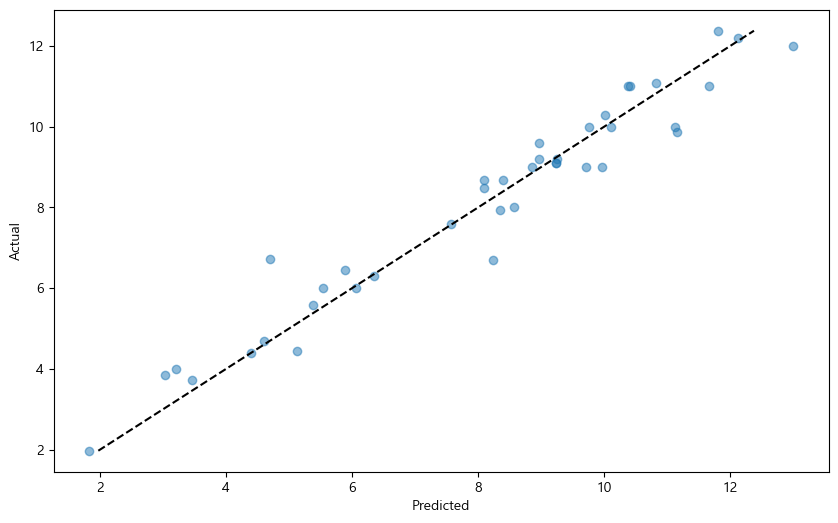

In [648]:
plt.figure(figsize = (10, 6))

plt.scatter(fin_pred, y_test, alpha = 0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "k--")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

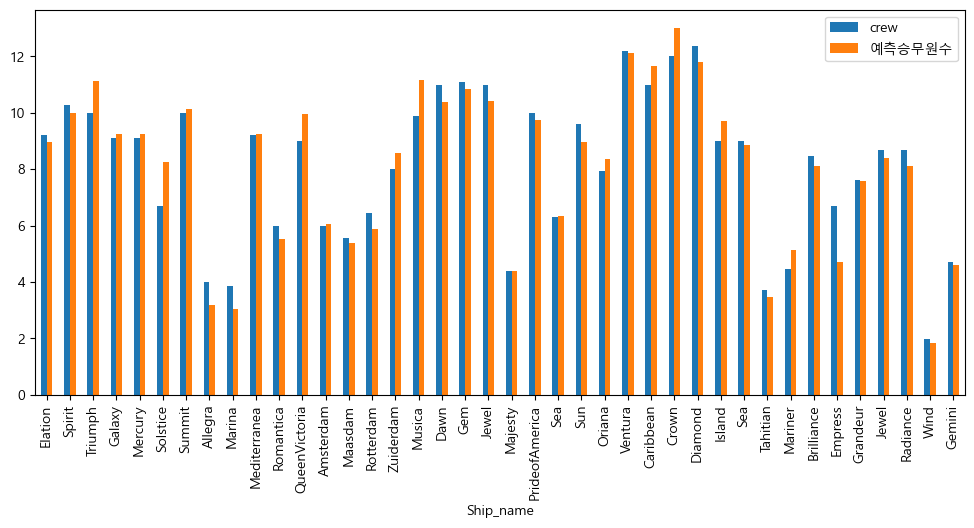

In [650]:
fig = plt.figure(figsize = (12, 5))
pred_df.plot(x = "Ship_name", y = ["crew", "예측승무원수"], kind = "bar", ax = plt.gca())
plt.show()

In [652]:
fin_lr.coef_, fin_lr.intercept_

(array([ 0.66064863, -0.93656726,  0.98014127,  3.33273909,  0.53666237,
        -0.70572909,  0.44608898, -0.64468972,  0.54304502,  0.67951358,
        -1.55169293,  0.50605332,  1.33489935]),
 7.881063350757189)

## PolynomialFeatures 적용

In [756]:
# PolynomialFeatures
poly_m = PolynomialFeatures(include_bias = False)
x_train_poly = poly_m.fit_transform(scaled_train[fin2_columns])
x_test_poly = poly_m.transform(scaled_test[fin2_columns])

In [758]:
lr_poly = LinearRegression()

In [760]:
lr_poly.fit(x_train_poly, y_train)

LinearRegression()

In [762]:
print(lr_poly.score(x_train_poly, y_train))
print(lr_poly.score(x_test_poly, y_test))

0.9551036550765312
0.9325002542710518


In [764]:
poly_pred = lr_poly.predict(x_test_poly)
print(f"mse: {mean_squared_error(y_test, poly_pred)}")

mse: 0.4535128872452489


In [790]:
# Ridge
# alpha 별 모델 생성
ridge = Ridge(alpha = 1)
ridge2 = Ridge(alpha = 2)
ridge3 = Ridge(alpha = 3)
ridge5 = Ridge(alpha = 5)

ridge.fit(x_train_poly, y_train)
ridge2.fit(x_train_poly, y_train)
ridge3.fit(x_train_poly, y_train)
ridge5.fit(x_train_poly, y_train)

Ridge(alpha=5)

In [792]:
# 모델 별 R-Square 산출
print("ridge R2")
print(ridge.score(x_train_poly, y_train))
print(ridge.score(x_test_poly, y_test))

print("ridge2 R2")
print(ridge2.score(x_train_poly, y_train))
print(ridge2.score(x_test_poly, y_test))

print("ridge3 R2")
print(ridge3.score(x_train_poly, y_train))
print(ridge3.score(x_test_poly, y_test))

print("ridge5 R2")
print(ridge5.score(x_train_poly, y_train))
print(ridge5.score(x_test_poly, y_test))

ridge R2
0.950506234137531
0.9169089808757209
ridge2 R2
0.9488855310411954
0.9195634360964271
ridge3 R2
0.9475000352408749
0.9203208804714279
ridge5 R2
0.9450285303601632
0.9202534336471595
